# Python & pandas DataFrame Technical Interview — Part 3
## Hands-on Questions, Financial Trades, Client Analytics and Worked Solutions

This is a **standalone, executable interview workbook** designed for a senior Python/Quant/ML/Data Engineer working with institutional client transactions, market data and risk. It builds on the themes in Parts 1–2, but requires **neither** notebook.

### How to practise

1. Run **Setup** once; it generates all datasets locally.
2. Work through Levels 1–3. Read the business problem, **write your own code in the TODO cell**, and articulate assumptions before opening the answer key.
3. Run all answer-key cells to verify your reasoning with actual data and assertions.
4. Attempt one mock interview (30–45 min) **without** looking at solutions.

**Coverage:** DataFrame selection; indexing; `loc`/`iloc`; filtering; assignment; nulls/duplicates; strings/regex; `merge`; time-aware `merge_asof`; `groupby`, `agg`, `transform`, `apply`; weighted metrics; pivot/melt; `resample`; rolling/expanding; ranking; outliers; feature leakage; optimisation; pandas testing; and communication.

**Expected study time:** ~7–10 hours across 3–4 sessions. Includes 28 substantive challenges, small follow-up questions, runnable solution cells, assertions and charts.

**All data are simulated.** USD notional and bp costs are normalised teaching proxies across products. They are **not** cash-flow-consistent derivative valuations or investment recommendations.

## Index and interview rules

| Module | Skills | Expected time |
|---|---|---:|
| Setup | reproducible trading dataset and dirty ingestion records | 15 min |
| Level 1: Core pandas | filter/index, dtypes, missing data, deduplication | 60–90 min |
| Level 2: Analyst tasks | joins, groupby, weighted metrics, pivot, reshape | 90–120 min |
| Level 3: Time and production | as-of joins, rolling windows, leakage, validations, performance | 90–120 min |
| Mock interviews | end-to-end client execution and behaviour assessment | 60–90 min |
| Solutions | 28 worked answers, invariants and discussions | review after trying |

In any live-coding interview, explain:

1. **Granularity:** one row per trade, client, date, or client-month?
2. **Time:** event time, quote time, ingestion time or business day? What was known *as of* the decision?
3. **Units and weights:** an average cost in bp, USD cost, or notional-weighted bp?
4. **Data integrity:** duplicates, corrections, nulls, outliers, currency, join cardinality and market-data staleness.
5. **Complexity and tests:** correctness first, then vectorisation and performance.

### Interview reminders

- `df.loc[rows, columns]` selects **labels**; `df.iloc[rows, columns]` selects **positions**.
- `.loc[a:b]` includes **both endpoint labels** when the index supports them; `.iloc[a:b]` excludes `b`.
- `groupby().agg()` reduces groups, while `groupby().transform()` preserves original row count.
- A left join that increases trade count often indicates a broken **many-to-one** key.
- For `merge_asof`, sort by the timestamp `on` key and use `direction='backward'` to prevent future quotes.

## Setup — packages and simulated financial datasets

Only Python, NumPy, pandas, Matplotlib and Seaborn are required. No external datasets or APIs.

### Data tables

| Variable | Grain | Content |
|---|---|---|
| `clients` | client | name, sector, country, risk tier |
| `client_versions` | client × effective date | historical risk-tier amendments |
| `products` | instrument | product family, asset, price scale |
| `quotes` | instrument × intraday timestamp | independently generated dealer mid quote |
| `fills_raw` | ingestion event | revisions, missing fields, bad values |
| `fills` | one valid fill | deduplicated, validated transaction table |
| `market` | business day | market regime and volatility index |

**Answer key convention:** names starting with `sol_` are solution outputs so your attempted variables can remain separate.

In [1]:
import re
from time import perf_counter
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED=2026
rng=np.random.default_rng(SEED)
pd.set_option('display.max_columns',30)
pd.set_option('display.width',145)
pd.set_option('display.float_format',lambda x:f'{x:,.3f}')
sns.set_theme(style='whitegrid',palette='deep')
plt.rcParams.update({'figure.figsize':(11,4),'axes.titlesize':12})
print('Python/pandas practice ready | pandas',pd.__version__)

Python/pandas practice ready | pandas 3.0.3


In [2]:
n_days=260
dates=pd.bdate_range('2025-01-02',periods=n_days)
daily_idx=np.arange(n_days)
regime=np.select([daily_idx<95,daily_idx<175],['Calm','Risk-off'],default='Recovery')
regime_scale=np.where(regime=='Risk-off',1.7,np.where(regime=='Recovery',1.25,1.0))
market=pd.DataFrame({'date':dates,'day_idx':daily_idx,'market_regime':regime,
                     'volatility_index':18*regime_scale+rng.normal(0,1.2,n_days)})

client_ids=[f'C{i:03d}' for i in range(1,25)]
clients=pd.DataFrame({
 'client_id':client_ids,
 'client_name':[f'Institutional Client {i:02d}' for i in range(1,25)],
 'client_sector':rng.choice(['Pension','Asset Manager','Hedge Fund','Insurance','Treasury'],24),
 'region':rng.choice(['UK','Europe','US'],24,p=[.48,.30,.22]),
 'risk_tier':rng.choice(['Low','Medium','High'],24,p=[.30,.40,.30]),
 'aum_usd_m':np.round(rng.lognormal(np.log(850),.48,24),1)})

products=pd.DataFrame([
 ('GILT5','BOND',98.0,.0022),('GILT10','BOND',102.0,.0028),
 ('CORP7','CREDIT',99.0,.004),('HY5','CREDIT',96.0,.0058),
 ('US_EQ_FUT','FUTURE',5100.0,.010),('UK_EQ_FUT','FUTURE',7900.0,.008),
 ('GBPUSD','FX',1.27,.004),('EURUSD','FX',1.09,.0038)],
 columns=['instrument','asset_class','initial_mid','daily_vol'])

# Slowly changing dimension (SCD) history: risk tiers may change at a later effective date.
history=[]
for c in clients.itertuples(index=False):
    history.append((c.client_id,dates[0],c.risk_tier))
    if int(c.client_id[1:]) % 3==0:
        later={'Low':'Medium','Medium':'High','High':'Medium'}[c.risk_tier]
        history.append((c.client_id,dates[150],later))
client_versions=pd.DataFrame(history,columns=['client_id','effective_from','risk_tier_asof'])
display(clients.head(5))
display(products)

,client_id,client_name,client_sector,region,risk_tier,aum_usd_m
0,C001,Institutional Client 01,Pension,Europe,Medium,"1,292.000"
1,C002,Institutional Client 02,Pension,Europe,High,636.300
2,C003,Institutional Client 03,Insurance,UK,High,592.600
3,C004,Institutional Client 04,Pension,UK,Low,794.300
4,C005,Institutional Client 05,Treasury,US,Medium,976.900


,instrument,asset_class,initial_mid,daily_vol
0,GILT5,BOND,98.000,0.002
1,GILT10,BOND,102.000,0.003
2,CORP7,CREDIT,99.000,0.004
3,HY5,CREDIT,96.000,0.006
4,US_EQ_FUT,FUTURE,"5,100.000",0.010
5,UK_EQ_FUT,FUTURE,"7,900.000",0.008
6,GBPUSD,FX,1.270,0.004
7,EURUSD,FX,1.090,0.004


In [3]:
# Simulate 4 dealer quote updates per business day and instrument.
quote_rows=[]
quote_id=0
for spec in products.itertuples(index=False):
    daily_shocks=rng.normal(0,spec.daily_vol,n_days)*regime_scale
    levels=spec.initial_mid*np.cumprod(1+daily_shocks)
    for d,day in enumerate(dates):
        for hour,minute in [(9,0),(11,0),(13,0),(15,0)]:
            quote_id+=1
            mid=levels[d]*(1+rng.normal(0,spec.daily_vol*.08))
            quote_rows.append((f'Q{quote_id:06d}',spec.instrument,
                day+pd.Timedelta(hours=hour,minutes=minute),day,float(mid)))
quotes=pd.DataFrame(quote_rows,columns=['quote_id','instrument','quote_ts','quote_date','mid'])

# Trades: 8,000 fills; time never precedes the first 09:00 quote.
N=8_000
fill_days=rng.integers(0,n_days,N)
fill_instruments=rng.choice(products.instrument.to_numpy(),N,p=[.14,.12,.13,.07,.15,.14,.14,.11])
fill_clients=rng.choice(client_ids,N)
fill_minutes=rng.integers(9*60+5,16*60,N)
trade_ts=pd.to_datetime(dates.values[fill_days])+pd.to_timedelta(fill_minutes,unit='m')

fills_base=pd.DataFrame({
 'fill_id':[f'T{i:06d}' for i in range(1,N+1)],
 'trade_ts':trade_ts,
 'trade_date':pd.to_datetime(dates.values[fill_days]),
 'client_id':fill_clients,
 'instrument':fill_instruments,
 'side':rng.choice([-1,1],N),
 'notional_usd':rng.uniform(1.5e6,16e6,N),
 'liquidity_score':rng.beta(4,2,N),
 'venue':rng.choice(['VOICE','RFQ','ELECTRONIC'],N,p=[.25,.45,.30]),
 'desk':rng.choice(['Rates','Credit','FX','Equities'],N),
 'version':np.ones(N,dtype=int)})

# Point-in-time quote matching is used ONLY to generate plausible executions.
# The resulting educational fill table does not expose the matched mid.
generator_join=pd.merge_asof(
   fills_base.sort_values('trade_ts'),
   quotes.sort_values('quote_ts')[['instrument','quote_ts','mid','quote_id']],
   left_on='trade_ts',right_on='quote_ts',by='instrument',direction='backward',
   tolerance=pd.Timedelta('8h'))
assert generator_join.mid.notna().all()
generator_join=generator_join.merge(market[['date','market_regime','volatility_index']],
               left_on='trade_date',right_on='date',validate='many_to_one')
generator_join['slippage_bps']=np.maximum(.1,1.2+4*(1-generator_join.liquidity_score)
       +.23*(generator_join.volatility_index-18)+rng.normal(0,1.1,N))
generator_join['spread_half_bps']=np.where(generator_join.instrument.str.startswith('GILT'),1.8,2.9)
generator_join['execution_price']=generator_join.mid*(1+generator_join.side*
    (generator_join.spread_half_bps+generator_join.slippage_bps)/10000)
generator_join['fee_usd']=np.maximum(5,1.4*generator_join.notional_usd/1e6)

fills=(generator_join[['fill_id','trade_ts','trade_date','client_id','instrument','side',
   'notional_usd','liquidity_score','venue','desk','execution_price','slippage_bps',
   'fee_usd','version']].sort_values('trade_ts').reset_index(drop=True))
fills['signed_notional_usd']=fills.notional_usd*fills.side

# Ingestion simulation: latest version overrides a few earlier records; missing fields and bad values.
corrections=fills.sample(40,random_state=42).copy()
corrections['version']=2
corrections['execution_price']*=1.00002
fills_raw=pd.concat([fills,corrections],ignore_index=True).sample(frac=1,random_state=23).reset_index(drop=True)
fills_raw.loc[10:34,'liquidity_score']=np.nan
fills_raw.loc[50:59,'venue']=None
fills_raw.loc[70:73,'notional_usd']=-2e6

print('Quote updates:',f'{len(quotes):,}','| clean fills:',f'{len(fills):,}',
      '| raw ingestion events:',f'{len(fills_raw):,}')
display(fills_raw.head(4))

Quote updates: 8,320 | clean fills: 8,000 | raw ingestion events: 8,040


,fill_id,trade_ts,trade_date,client_id,instrument,side,notional_usd,liquidity_score,venue,desk,execution_price,slippage_bps,fee_usd,version,signed_notional_usd
0,T006929,2025-08-29 14:20:00,2025-08-29,C013,GBPUSD,1,"10,108,599.791",0.776,RFQ,Credit,1.289,5.346,14.152,1,"10,108,599.791"
1,T006385,2025-04-17 10:43:00,2025-04-17,C002,UK_EQ_FUT,1,"2,071,169.695",0.926,ELECTRONIC,FX,"6,949.903",3.524,5.000,1,"2,071,169.695"
2,T004103,2025-11-27 12:20:00,2025-11-27,C008,EURUSD,1,"4,308,013.788",0.816,VOICE,Credit,1.052,2.433,6.031,1,"4,308,013.788"
3,T004326,2025-05-20 12:08:00,2025-05-20,C003,UK_EQ_FUT,1,"8,084,095.529",0.641,VOICE,FX,"6,717.275",4.160,11.318,1,"8,084,095.529"


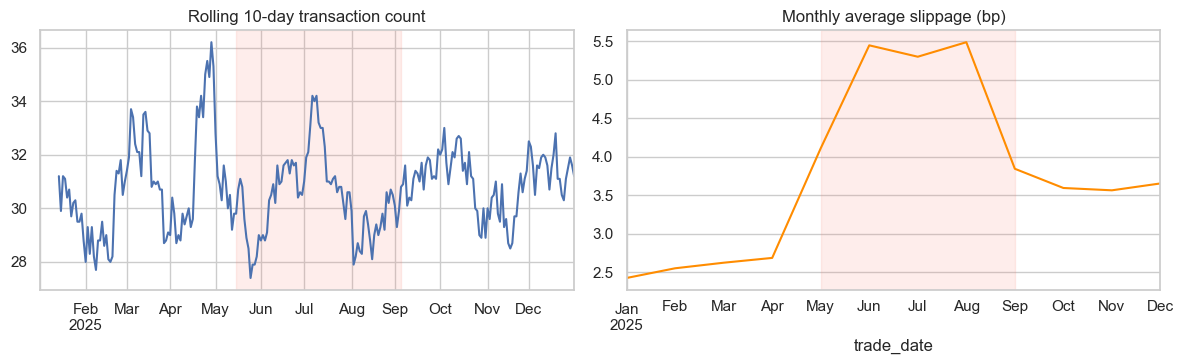

In [4]:
fig,ax=plt.subplots(1,2,figsize=(12,3.8))
fills.groupby('trade_date').size().reindex(dates,fill_value=0).rolling(10).mean().plot(ax=ax[0],title='Rolling 10-day transaction count')
fills.set_index('trade_date').slippage_bps.resample('MS').mean().plot(ax=ax[1],title='Monthly average slippage (bp)',color='darkorange')
for a in ax:a.axvspan(dates[95],dates[175],alpha=.14,color='salmon')
fig.tight_layout();plt.show()

# Level 1 — Core DataFrame fluency

Treat each exercise as if you are screen-sharing in a live interview. Attempt the TODO cell first; worked solutions are consolidated in the answer key. **Do not overwrite `fills_raw`, `fills`, `quotes`, `clients` or `products`** in your attempts.

## Q01 — Inspect a DataFrame (5 min)

1. Print shape, columns, dtypes, first three rows and descriptive statistics for numerical fields.
2. Identify the **primary key** of `fills_raw`. Is it unique?
3. Explain the difference between `df.head()`, `df.info()`, `df.describe()` and `df.memory_usage(deep=True)`.

**Expected:** `fills_raw` contains 40 revisions sharing a fill ID; it is an ingestion log, not yet a unique-fill table.

In [5]:
# TODO Q01 — inspect fills_raw.

## Q02 — Select, filter, locate (7 min)

Return `fill_id`, `client_id`, `instrument`, `notional_usd` for valid **BUY** bond trades above $8m. Sort descending by notional. State when you would use `.loc`, `.iloc`, `.query()` and `.isin()`.

**Pitfall:** In pandas boolean filters, wrap each comparison in parentheses before combining with `&` or `|`.

In [6]:
# TODO Q02 — use .loc with a compound mask, then .sort_values.

## Q03 — Assign without chained-indexing surprises (7 min)

On a **copy**, add a column `ticket_band` with three labels: `Small` (below $5m), `Medium` ($5m–$10m), and `Large` (above $10m). Use `pd.cut` or `np.select`. Test exact boundaries $5m and $10m.

Why can `df[df.side==1]['ticket_band']='Large'` fail to change `df` reliably?

In [7]:
# TODO Q03 — ticket bands. Include edge-case assertions.

## Q04 — Nulls and dirty numbers (10 min)

From `fills_raw`:

1. Summarise missing values per column.
2. Flag invalid non-positive notionals and missing liquidity/venue.
3. Explain which fields should cause a row to be **quarantined** and which can be filled with `UNKNOWN`.
4. Add a safe `pd.to_numeric(errors='coerce')` example for a string such as `"12,000"` or `"oops"`.

**Important:** Imputation for modelling must be fitted to training data only; indiscriminate imputation can hide data-quality failures.

In [8]:
# TODO Q04 — null checks, type conversion, quarantine rule.

## Q05 — Deduplicate corrected fills (10 min)

Keep the highest `version` of each `fill_id`, then exclude invalid non-positive notionals. Verify uniqueness and reconcile total notional.

**Bonus:** What happens if two records have identical `fill_id` and `version`? Define an ingestion timestamp tie-breaker or quarantine ambiguity.

In [9]:
# TODO Q05 — sort by version, drop_duplicates(keep='last'), validate.

## Q06 — Work with strings and regex (8 min)

Extract product prefixes from `instrument`: `GILT`, `CORP`, `HY`, `US`, `UK`, `GBPUSD`, `EURUSD`. Use `.str.extract()` and discuss regex anchors. Create `is_fx` with `.isin(['GBPUSD','EURUSD'])`.

Explain: why might `str.contains('US')` accidentally match unrelated codes? How do `na=False`, raw strings and word boundaries help?

In [10]:
# TODO Q06 — string methods, regex and null handling.

## Q07 — Indexing and MultiIndex (8 min)

Make a `(client_id, trade_date)` MultiIndex sorted by index; retrieve all fills for `C001`, then all fills for `C001` in a selected date range. Explain why a non-unique MultiIndex can still be useful for transaction tables.

In [11]:
# TODO Q07 — .set_index, .sort_index, .loc, pd.IndexSlice.

# Level 2 — Financial analytics with pandas

## Q08 — Safe reference-data join (10 min)

Join each fill to `clients` and `products`. Show that the result has **exactly the same number of rows** as `fills`. Use `validate='many_to_one'`, inspect unmatched keys, and explain why unconstrained joins can duplicate USD notional and distort P&L.

In [12]:
# TODO Q08 — joins and cardinality tests.

## Q09 — Groupby with named aggregations (10 min)

By `client_id` and `asset_class`, compute:

- Trade count
- Total USD notional
- Mean and median ticket size
- Mean slippage in bp
- Net signed notional

Explain `agg` versus `transform` versus `apply`. What is the **granularity** of the result?

In [13]:
# TODO Q09 — groupby(...).agg(count=(...), total=(...), ...).

## Q10 — Notional-weighted mean (10 min)

Compute notional-weighted slippage for each client:

\(\bar{s}_{w}=\frac{\sum_i N_i s_i}{\sum_i N_i}\)

Show why it can differ from the simple arithmetic average when ticket sizes differ. Assert that each weighted average lies between its group's minimum and maximum slippage.

In [14]:
# TODO Q10 — use weighted numerator = notional * slippage, then groupby sums.

## Q11 — Rank top transactions within each client (8 min)

Return the largest three fills by **notional** per client, sorted descending within each client. Implement in two ways: `sort_values(...).groupby(...).head(3)` and a rank-based approach.

**Follow-up:** What happens with ties? Choose an explicit deterministic tie-breaker.

In [15]:
# TODO Q11 — group-wise top-N, tie handling.

## Q12 — Pivot, crosstab and heatmap (10 min)

Create a client × product-family matrix of notional in millions. Show row-normalised product shares and plot a heatmap for the 12 highest-turnover clients.

Explain `pivot()` versus `pivot_table()` and why **duplicates** require aggregation for the latter.

In [16]:
# TODO Q12 — pivot_table(..., aggfunc='sum', fill_value=0).

## Q13 — Reshape wide ↔ long (8 min)

Take your wide client/product matrix, reset the index and use `melt` to produce rows `(client_id, asset_class, notional_usd_m)`. Rebuild the matrix and check equality.

When is a **long** table more convenient for plotting and grouping?

In [17]:
# TODO Q13 — melt, pivot_table, round-trip assertion.

## Q14 — Per-row percentages with transform (8 min)

For each fill, calculate the fraction of that **client's total** notional represented by the fill without changing the number of rows. Then sum the fractions within each client and verify they equal 1.

In [18]:
# TODO Q14 — transform('sum') and divide.

## Q15 — Quantiles and anomalous fills (10 min)

Flag fills whose slippage exceeds the **95th percentile of their asset class**. Use `groupby('asset_class').transform('quantile', .95)` or equivalent. Compare alert counts across products.

**Senior-level caveat:** Is a 95th-percentile policy a signal of misconduct or poor performance? No—it is only a distributional outlier screen needing context.

In [19]:
# TODO Q15 — within-asset percentile, not one global threshold.

# Level 3 — Time-series, financial controls and pandas performance

## Q16 — Resample transaction flows (10 min)

Compute business-day client turnover and fill count, then weekly volumes. Ensure the business-day index includes dates with **zero trades** for a given client; `groupby` alone omits those dates.

**Interview follow-up:** What is the difference between calendar days and exchange/business calendars? Which is appropriate for returns and VWAP windows?

In [20]:
# TODO Q16 — .resample('B'), .reindex(dates, fill_value=0).

## Q17 — Causal rolling statistics (12 min)

For a selected client, compute 20-business-day rolling average turnover and its *previous* 60-day mean and standard deviation to flag unusually large daily turnover.

Use `.shift(1)` to prevent today's observation contaminating its own prior baseline. Plot daily turnover, rolling means and outliers.

In [21]:
# TODO Q17 — rolling(20), shift(1).rolling(60), alert if z>3.

## Q18 — Latest quote at or before a trade (`merge_asof`) (15 min)

Match fills to the most recent quote of **the same instrument** with timestamp **not later than** execution time. Reject quotes older than eight hours. Calculate execution disadvantage:

`cost_bps = side * (execution_price − mid) / mid * 10_000`.

Explain:

- Why a normal equality join on date can be wrong.
- Why `direction='nearest'` can leak a quote published after the fill.
- Why both inputs must be sorted by their time keys.
- How to handle stale quotes and missing instruments.

In [22]:
# TODO Q18 — pd.merge_asof with by='instrument', direction='backward', tolerance=...

## Q19 — Causal risk-tier changes (`merge_asof`) (12 min)

An account's risk tier may change during the year. Join `client_versions` to historical fills using the tier **effective on the trade date**. Why would joining the latest/current tier to *all historical trades* introduce retrospective bias?

In [23]:
# TODO Q19 — as-of join by client_id and effective_from.

## Q20 — Lead, lag, percent change and look-ahead (10 min)

For each instrument's daily mid, calculate daily returns and an **historical** 5-day momentum signal using previous observed data. Compare `.shift(1)` and `.shift(-1)` and state why using tomorrow's return as a feature is leakage.

In [24]:
# TODO Q20 — sort, groupby('instrument'), pct_change, shift, rolling.

## Q21 — Client exposure and Herfindahl concentration (10 min)

For each client, compute total notional by asset class, each class's share, and HHI = sum of squared shares. Interpret HHI near 1 versus smaller values.

**Follow-up:** Why is notional share not a substitute for market-risk sensitivity or VaR?

In [25]:
# TODO Q21 — unstack, div(row totals), pow(2).sum(axis=1).

## Q22 — Identify client behaviour change (15 min)

Split the observation period into early and late halves. For each client, compare **FX notional share**, sell-side share and fills/day across the two halves. Rank clients by absolute change in FX share and investigate whether shifts are market-wide.

This resembles Part 2, but focuses on the DataFrame mechanics rather than unsupervised modelling.

In [26]:
# TODO Q22 — assign period, groupby, pivot and change features.

## Q23 — Efficient vectorisation (10 min)

Calculate the same execution-price cost formula using:

1. A Python loop over `itertuples()`
2. A pandas vectorised expression

Benchmark both on the same table, assert numerical equality, and discuss the limits of `apply(axis=1)`.

In [27]:
# TODO Q23 — perf_counter, np.allclose, never compare different work.

## Q24 — Robust data-pipeline checks (10 min)

Write assertions for:

- Fill IDs unique after correction handling
- All notionals positive and sides ±1
- No negative slippage
- Joins preserve expected row counts
- Matched quotes are not from the future
- Daily totals reconcile to fill totals

**Production nuance:** Assertions are useful in notebooks, but pipelines also need structured quality reports and explicit reject/quarantine decisions.

In [28]:
# TODO Q24 — assertions and a validation report.

## Q25 — Pure Python plus pandas (10 min)

Write a small, type-annotated function that takes a sequence of `(client_id, value)` pairs and accumulates totals in a dictionary using `defaultdict(float)`; then reproduce its result with a pandas groupby. Discuss time complexity and when pandas is overkill.

In [29]:
# TODO Q25 — collections.defaultdict + a DataFrame equivalence check.

## Q26 — Sliding-window questions (10 min)

Given daily notional flows for one client, find the contiguous **five-business-day** window with maximum turnover. Implement a NumPy/pandas rolling solution and a pure-Python O(n) running-sum solution.

**Follow-up:** What changes if missing business days must count as zero?

In [30]:
# TODO Q26 — rolling(5).sum() and a rolling-sum algorithm.

## Q27 — Debug a deliberately broken analysis (10 min)

Identify three problems before running this pseudocode:

```python
all_data = fills.merge(products, on='asset_class')
all_data['new'] = all_data[all_data.side == 1]['notional_usd'] * 2
signals = quotes.groupby('instrument').mid.shift(-1)
```

Hints: key/cardinality, indexing/assignment and temporal leakage. Write the corrected version and explain what tests would catch the bugs.

In [31]:
# TODO Q27 — corrected join, safe assignment and past-only signal.

## Q28 — Design a pandas ETL function (15 min)

Implement `clean_trade_events(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]` that returns:

1. An accepted table with one latest valid version per fill.
2. A rejected table containing non-positive notionals (with a reason).

Guarantee **idempotency**: running the function twice on accepted output should not change its rows or values. Do not mutate the caller's DataFrame.

In [32]:
# TODO Q28 — clean_trade_events with tests and explicit reject reasons.

# Visual interview case studies

These visuals are built from the same data. Before looking at each plot, predict what should happen given the known synthetic stress regime. Use a quantitative sentence to describe **what is shown**, **why it matters** and **what it cannot prove**.

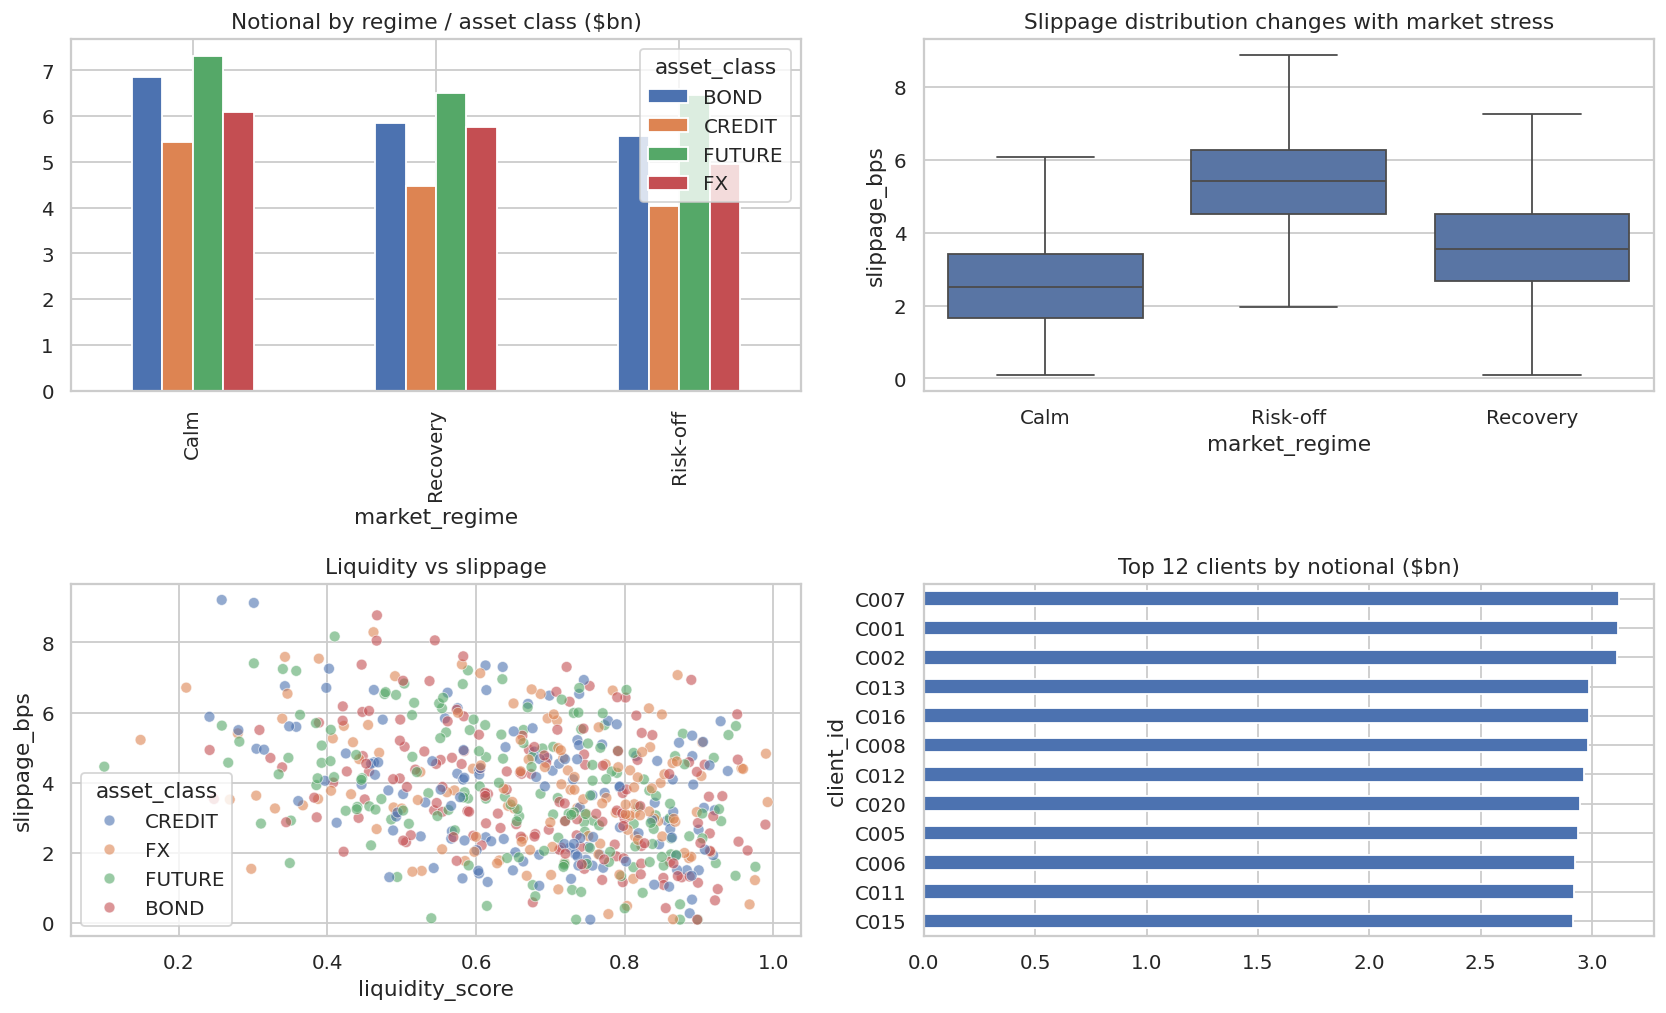

In [33]:
v= fills.merge(products[['instrument','asset_class']],on='instrument',validate='many_to_one')
v=v.merge(market[['date','market_regime']],left_on='trade_date',right_on='date',validate='many_to_one')
fig,axs=plt.subplots(2,2,figsize=(13,8))
v.groupby(['market_regime','asset_class']).notional_usd.sum().unstack(fill_value=0).div(1e9).plot(kind='bar',ax=axs[0,0],title='Notional by regime / asset class ($bn)')
sns.boxplot(data=v,x='market_regime',y='slippage_bps',order=['Calm','Risk-off','Recovery'],ax=axs[0,1],showfliers=False)
axs[0,1].set_title('Slippage distribution changes with market stress')
sns.scatterplot(data=v.sample(600,random_state=SEED),x='liquidity_score',y='slippage_bps',hue='asset_class',alpha=.6,ax=axs[1,0]);axs[1,0].set_title('Liquidity vs slippage')
v.groupby('client_id').notional_usd.sum().nlargest(12).div(1e9).sort_values().plot(kind='barh',ax=axs[1,1],title='Top 12 clients by notional ($bn)')
fig.tight_layout();plt.show()

## Mock interview A — Execution quality dashboard (40 min)

**Scenario:** A senior sales trader asks which institutional clients have the least attractive trade executions in the last 60 business days.

Deliver a function with a clear input contract that:

1. Uses only fills and quotes available **at the evaluation timestamp**.
2. Filters to the last 60 business days.
3. Computes each fill's transaction-cost bp using the correct quote and side.
4. Calculates client/asset-level **notional-weighted bp** and total execution cost in USD.
5. Ranks only clients with a minimum $100m turnover to avoid tiny denominators.
6. Includes one explanatory chart and flags missing/stale quote matches.

**Interviewers may ask:** Which quote is the correct comparator? Is it the independent reference mid, executable bid/ask, arrival mid or VWAP? How do you avoid cross-currency value comparisons? Why can latency and trade urgency confound cost comparisons?

**Acceptance checks:** no future quote, no double counting, weighting explained, row-count reconciliation, explicit review threshold.

In [34]:
# MOCK A — 40-minute whiteboard/live-coding space. Try without the answer key.

## Mock interview B — Which clients changed trading behaviour? (35 min)

Compute client/product shares and sell-side ratios in consecutive 40-business-day windows. Identify top migrations, describe whether the shift happened across peers, and make clear that a behavioural change is not proof of intent or distress.

**Deliverables:** client × window features, `abs_change_fx_share`, group-level benchmark, timeline chart for one client, 3 tests.

In [35]:
# MOCK B — client-window aggregation and change detection.

## Mock interview C — What broke the data pipeline? (30 min)

Your reported daily turnover doubled after deploying a new product-master feed. Diagnose using join cardinality and source-data checks. Then propose a recoverable fix, a unit test and a production monitor. Do **not** silently delete trades to make numbers agree.

**Hint:** common failures include duplicate reference keys, many-to-many merges, implicit null matching and incorrect as-of versions.

# Worked answer key

The exercises above intentionally contain **commented TODO cells**. This section is executable and verified, so you can compare your own implementation. It does not require your TODO variables.

## Solutions 01–07 — Selection, cleaning and indexing

In [36]:
# Q01: inspection and key check
print('Shape',fills_raw.shape,'| unique fill IDs',fills_raw.fill_id.nunique())
print('Missing fields:');display(fills_raw.isna().sum().to_frame('missing'))
display(fills_raw[['notional_usd','slippage_bps','liquidity_score']].describe().round(2))
assert len(fills_raw)-fills_raw.fill_id.nunique()==40

# Q02: filter and sort
sol_bond_codes=products.loc[products.asset_class=='BOND','instrument']
sol_large_buys=(fills.loc[(fills.side==1)&fills.instrument.isin(sol_bond_codes)&
              (fills.notional_usd>8e6),['fill_id','client_id','instrument','notional_usd']]
              .sort_values('notional_usd',ascending=False))
print('Large bond buys:',len(sol_large_buys));display(sol_large_buys.head(5))

# Q03: binned tickets; explicit inclusion of right-hand endpoint at 5/10m.
sol_bands=fills.copy()
sol_bands['ticket_band']=pd.cut(sol_bands.notional_usd,bins=[0,5e6,10e6,np.inf],
                               labels=['Small','Medium','Large'],right=True)
assert str(pd.cut(pd.Series([5e6]),[0,5e6,10e6,np.inf],labels=['Small','Medium','Large']).iloc[0])=='Small'
assert str(pd.cut(pd.Series([10e6]),[0,5e6,10e6,np.inf],labels=['Small','Medium','Large']).iloc[0])=='Medium'
display(sol_bands.ticket_band.value_counts())

Shape (8040, 15) | unique fill IDs 8000
Missing fields:
Large bond buys: 574


,missing
fill_id,0
trade_ts,0
trade_date,0
client_id,0
instrument,0
side,0
notional_usd,0
liquidity_score,25
venue,10
desk,0


,notional_usd,slippage_bps,liquidity_score
count,"8,040.000","8,040.000","8,015.000"
mean,"8,657,827.910",3.770,0.670
std,"4,193,593.180",1.760,0.180
min,"-2,000,000.000",0.100,0.080
25%,"5,042,703.010",2.470,0.550
50%,"8,653,844.980",3.690,0.690
75%,"12,237,162.960",4.990,0.810
max,"15,999,941.000",10.010,1.000


,fill_id,client_id,instrument,notional_usd
6237,T000742,C010,GILT10,"15,962,888.976"
195,T004135,C008,GILT5,"15,951,345.098"
3795,T007966,C006,GILT10,"15,932,269.165"
1039,T006543,C007,GILT5,"15,920,663.998"
5948,T002670,C020,GILT5,"15,920,257.652"


ticket_band
Large     3251
Medium    2759
Small     1990
Name: count, dtype: int64

In [37]:
# Q04: null/bad-value diagnostics; preserve every original record for audit.
sol_bad=(fills_raw.notional_usd<=0)
sol_missing=fills_raw[['liquidity_score','venue']].isna().sum()
print('Bad notional events:',int(sol_bad.sum()),'| missing fields:');display(sol_missing)
sol_str=pd.Series(['12,000','oops','43.5'])
sol_numeric=pd.to_numeric(sol_str.str.replace(',','',regex=False),errors='coerce')
display(pd.DataFrame({'raw':sol_str,'parsed':sol_numeric}))

# Q05: keep highest-version fill, reject invalid records; never mutate fills_raw.
sol_latest=(fills_raw.sort_values(['fill_id','version'])
            .drop_duplicates('fill_id',keep='last').copy())
sol_rejected=sol_latest.loc[sol_latest.notional_usd<=0].copy()
sol_accepted=sol_latest.loc[sol_latest.notional_usd>0].copy()
assert sol_latest.fill_id.is_unique and sol_accepted.fill_id.is_unique
print('Latest unique IDs:',len(sol_latest),'| rejected:',len(sol_rejected))

# Q06: use explicit anchored patterns where the code prefix has meaning.
sol_prefix=fills.instrument.str.extract(r'^(GILT|CORP|HY|US|UK|GBPUSD|EURUSD)',expand=False)
sol_is_fx=fills.instrument.isin(['GBPUSD','EURUSD'])
assert sol_prefix.notna().all() and int(sol_is_fx.sum())>0
display(pd.DataFrame({'prefix':sol_prefix,'is_fx':sol_is_fx}).head(4))

# Q07: MultiIndex need not be unique for event-level data.
sol_indexed=fills.set_index(['client_id','trade_date']).sort_index()
sol_one_client=sol_indexed.loc['C001']
sol_period=sol_one_client.loc[dates[35]:dates[65]]
print('C001 fills:',len(sol_one_client),'| selected window:',len(sol_period))

Bad notional events: 4 | missing fields:
Latest unique IDs: 8000 | rejected: 4
C001 fills: 351 | selected window: 53


liquidity_score    25
venue              10
dtype: int64

,raw,parsed
0,"12,000","12,000.000"
1,oops,NaN
2,43.5,43.500


,prefix,is_fx
0,CORP,False
1,CORP,False
2,GILT,False
3,EURUSD,True


## Solutions 08–15 — Joins, grouping, weighting and reshaping

In [38]:
# Q08: reference joins with explicit cardinality constraints.
sol_enriched=(fills.merge(clients,on='client_id',how='left',validate='many_to_one',indicator='_client_merge')
              .merge(products,on='instrument',how='left',validate='many_to_one',indicator='_product_merge'))
assert len(sol_enriched)==len(fills)
assert sol_enriched._client_merge.eq('both').all() and sol_enriched._product_merge.eq('both').all()
print('Safe join rows:',len(sol_enriched))

# Q09: named group aggregates
sol_groups=sol_enriched.groupby(['client_id','asset_class']).agg(
      trade_count=('fill_id','count'),
      notional_usd=('notional_usd','sum'),
      mean_ticket_usd=('notional_usd','mean'),
      median_ticket_usd=('notional_usd','median'),
      mean_slippage_bps=('slippage_bps','mean'),
      net_signed_notional_usd=('signed_notional_usd','sum')).reset_index()
display(sol_groups.head(7))

# Q10: value-weighted slippage = sum(weight*rate)/sum(weight)
sol_cost=sol_enriched.assign(weighted_bp_num=lambda d:d.slippage_bps*d.notional_usd)
sol_weighted=(sol_cost.groupby('client_id').agg(
        numerator=('weighted_bp_num','sum'),denominator=('notional_usd','sum')))
sol_weighted['weighted_slippage_bps']=sol_weighted.numerator/sol_weighted.denominator
sol_simple=sol_enriched.groupby('client_id').slippage_bps.mean()
print('Simple vs notional-weighted averages:')
display(pd.DataFrame({'simple':sol_simple,'weighted':sol_weighted.weighted_slippage_bps}).head(6))
assert (sol_weighted.weighted_slippage_bps>=sol_enriched.groupby('client_id').slippage_bps.min()-1e-8).all()
assert (sol_weighted.weighted_slippage_bps<=sol_enriched.groupby('client_id').slippage_bps.max()+1e-8).all()

Safe join rows: 8000
Simple vs notional-weighted averages:


,client_id,asset_class,trade_count,notional_usd,mean_ticket_usd,median_ticket_usd,mean_slippage_bps,net_signed_notional_usd
0,C001,BOND,89,"766,357,954.220","8,610,763.531","7,776,412.091",3.766,"-7,891,760.786"
1,C001,CREDIT,63,"527,226,944.177","8,368,681.654","8,015,612.473",4.002,"-44,445,659.220"
2,C001,FUTURE,112,"1,052,715,518.527","9,399,245.701","10,032,601.009",4.027,"97,962,830.964"
3,C001,FX,87,"773,030,356.924","8,885,406.401","8,587,939.615",3.548,"-125,057,788.843"
4,C002,BOND,99,"910,214,214.988","9,194,082.980","9,223,347.434",3.763,"50,997,126.836"
5,C002,CREDIT,78,"633,139,120.469","8,117,168.211","7,920,580.166",3.561,"-2,514,215.126"
6,C002,FUTURE,103,"885,956,760.965","8,601,521.951","8,823,548.107",3.690,"77,176,116.417"


,simple,weighted
client_id,,
C001,3.838,3.817
C002,3.687,3.649
C003,3.812,3.791
C004,3.798,3.742
C005,3.687,3.761
C006,3.744,3.710


Top trades: 72


,fill_id,trade_ts,trade_date,client_id,instrument,side,notional_usd,liquidity_score,venue,desk,execution_price,slippage_bps,fee_usd,version,signed_notional_usd
7195,T004348,2025-11-26 12:28:00,2025-11-26,C001,GILT10,1,"15,913,453.303",0.588,ELECTRONIC,Rates,93.857,5.312,22.279,1,"15,913,453.303"
6368,T001301,2025-10-17 15:22:00,2025-10-17,C001,US_EQ_FUT,-1,"15,882,734.258",0.676,RFQ,Equities,"6,827.675",4.735,22.236,1,"-15,882,734.258"
7238,T004015,2025-11-27 15:05:00,2025-11-27,C001,GBPUSD,-1,"15,827,806.037",0.830,ELECTRONIC,Equities,1.264,3.319,22.159,1,"-15,827,806.037"
7194,T003761,2025-11-26 12:03:00,2025-11-26,C002,US_EQ_FUT,-1,"15,975,787.812",0.399,VOICE,FX,"6,331.679",4.120,22.366,1,"-15,975,787.812"
1989,T005602,2025-04-03 11:02:00,2025-04-03,C002,EURUSD,-1,"15,892,286.045",0.788,RFQ,Equities,1.049,1.989,22.249,1,"-15,892,286.045"


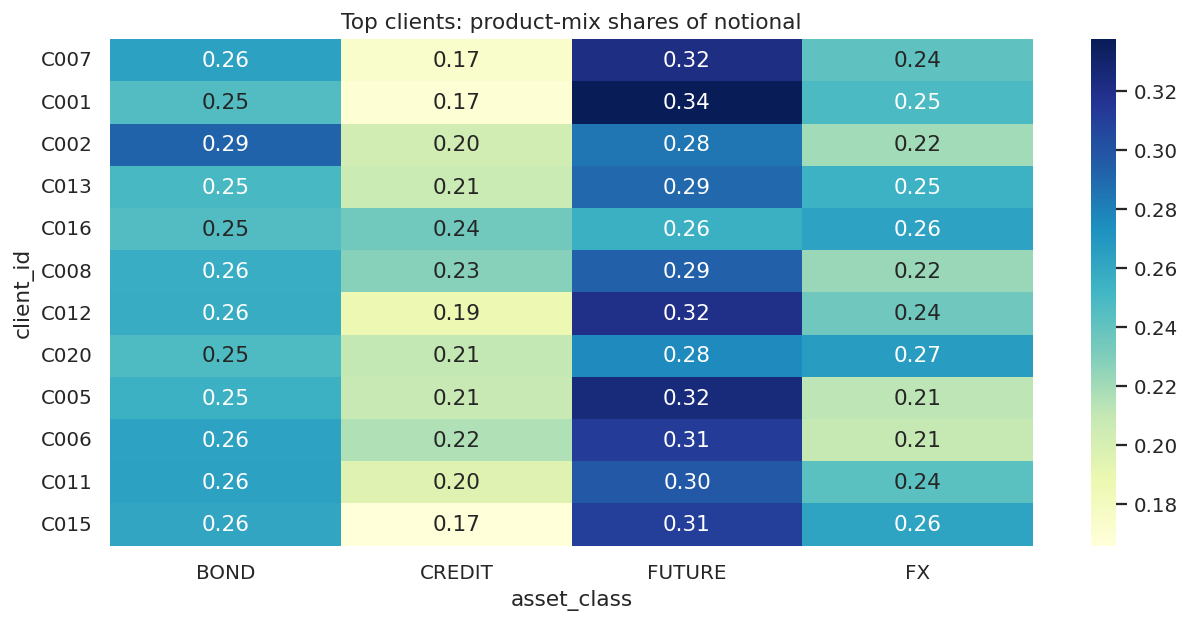

,sum,mean
asset_class,,
BOND,106,0.050
CREDIT,81,0.050
FUTURE,118,0.050
FX,97,0.050


In [39]:
# Q11: top-3 per client with deterministic sort on fill ID as tie-breaker.
sol_top3=(fills.sort_values(['client_id','notional_usd','fill_id'],ascending=[True,False,True])
          .groupby('client_id',sort=False).head(3))
sol_ranked=fills.assign(ticket_rank=fills.groupby('client_id').notional_usd.rank(method='first',ascending=False))
assert sol_top3.groupby('client_id').size().eq(3).all()
print('Top trades:',len(sol_top3));display(sol_top3.head(5))

# Q12: client × asset-class notional matrix, expressed in $m
sol_pivot=sol_enriched.pivot_table(index='client_id',columns='asset_class',
                   values='notional_usd',aggfunc='sum',fill_value=0)/1e6
sol_shares=sol_pivot.div(sol_pivot.sum(axis=1),axis=0)
assert np.allclose(sol_shares.sum(axis=1),1)
fig,ax=plt.subplots(figsize=(10,5))
hot_clients=sol_pivot.sum(axis=1).nlargest(12).index
sns.heatmap(sol_shares.loc[hot_clients],cmap='YlGnBu',annot=True,fmt='.2f',ax=ax)
ax.set_title('Top clients: product-mix shares of notional');plt.tight_layout();plt.show()

# Q13: melt wide to long and round-trip; preserve original column order.
sol_long=sol_pivot.reset_index().melt(id_vars='client_id',var_name='asset_class',value_name='notional_usd_m')
sol_rebuilt=sol_long.pivot(index='client_id',columns='asset_class',values='notional_usd_m')
pd.testing.assert_frame_equal(sol_pivot,sol_rebuilt.loc[sol_pivot.index,sol_pivot.columns],check_names=True)

# Q14: groupby transform preserves fill grain.
sol_fraction=fills.notional_usd/fills.groupby('client_id').notional_usd.transform('sum')
assert np.allclose(sol_fraction.groupby(fills.client_id).sum().to_numpy(),1)

# Q15: asset-relative 95th-percentile outlier screen.
sol_threshold=sol_enriched.groupby('asset_class').slippage_bps.transform('quantile',.95)
sol_outliers=sol_enriched.assign(high_cost=sol_enriched.slippage_bps>sol_threshold)
display(sol_outliers.groupby('asset_class').high_cost.agg(['sum','mean']))

## Solutions 16–22 — Time series, as-of joins and client migration

,notional_usd,fills
2025-01-03,"23,439,840.605",3
2025-01-10,"44,472,652.337",5
2025-01-17,"26,217,590.340",5
2025-01-24,"36,001,309.093",4
2025-01-31,"28,145,831.065",3


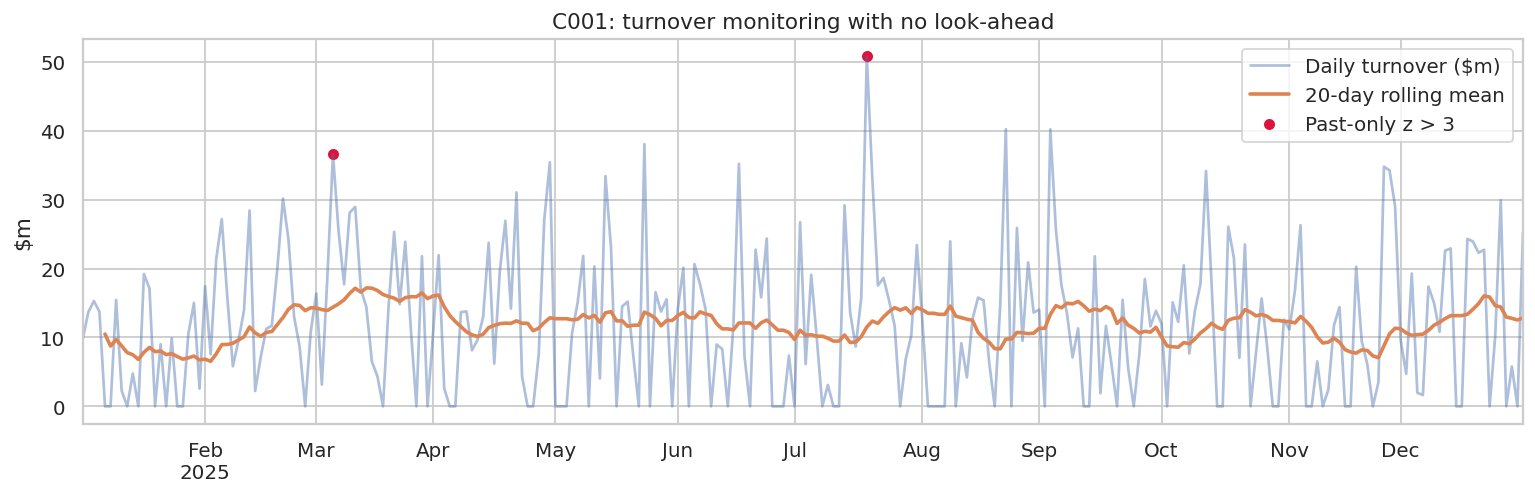

,fill_id,instrument,quote_ts,trade_ts,mid,execution_price,execution_cost_bps
0,T001898,CORP7,2025-01-02 09:00:00,2025-01-02 09:12:00,98.228,98.163,6.614
1,T003857,CORP7,2025-01-02 09:00:00,2025-01-02 09:13:00,98.228,98.190,3.851
2,T006092,GILT5,2025-01-02 09:00:00,2025-01-02 09:14:00,98.108,98.090,1.900
3,T005975,EURUSD,2025-01-02 09:00:00,2025-01-02 09:25:00,1.087,1.087,3.774
4,T001379,GILT10,2025-01-02 09:00:00,2025-01-02 09:32:00,102.470,102.507,3.635


In [40]:
# Q16: include zero-trade business dates for selected client.
sol_daily=(fills.loc[fills.client_id=='C001'].set_index('trade_date')
           .resample('B').agg(notional_usd=('notional_usd','sum'),fills=('fill_id','count'))
           .reindex(dates,fill_value=0))
sol_weekly=sol_daily.resample('W-FRI').sum()
assert np.isclose(sol_daily.notional_usd.sum(),fills.loc[fills.client_id=='C001','notional_usd'].sum())
display(sol_weekly.head())

# Q17: past-only anomaly baseline on a daily time series.
sol_vol=sol_daily.notional_usd/1e6
sol_mean_20=sol_vol.rolling(20,min_periods=5).mean()
sol_past_mean=sol_vol.shift(1).rolling(60,min_periods=30).mean()
sol_past_sd=sol_vol.shift(1).rolling(60,min_periods=30).std()
sol_z=(sol_vol-sol_past_mean)/sol_past_sd.replace(0,np.nan)
sol_alert=sol_z>3
fig,ax=plt.subplots(figsize=(12,4))
sol_vol.plot(ax=ax,alpha=.45,label='Daily turnover ($m)')
sol_mean_20.plot(ax=ax,lw=2,label='20-day rolling mean')
ax.scatter(sol_vol[sol_alert].index,sol_vol[sol_alert],s=26,color='crimson',label='Past-only z > 3')
ax.set(title='C001: turnover monitoring with no look-ahead',ylabel='$m');ax.legend();plt.tight_layout();plt.show()

# Q18: match the prior quote only, within an 8-hour tolerance.
sol_matched=pd.merge_asof(
    fills.sort_values('trade_ts'),
    quotes[['instrument','quote_ts','mid','quote_id']].sort_values('quote_ts'),
    left_on='trade_ts',right_on='quote_ts',by='instrument',direction='backward',
    tolerance=pd.Timedelta('8h'))
assert len(sol_matched)==len(fills) and sol_matched.mid.notna().all()
assert (sol_matched.quote_ts<=sol_matched.trade_ts).all()
sol_matched['execution_cost_bps']=(sol_matched.side*(sol_matched.execution_price-sol_matched.mid)
                                     /sol_matched.mid*10000)
sol_matched['execution_cost_usd']=sol_matched.execution_cost_bps*sol_matched.notional_usd/10000
display(sol_matched[['fill_id','instrument','quote_ts','trade_ts','mid','execution_price','execution_cost_bps']].head())

In [41]:
# Q19: risk tier effective at fill date, not the present-day tier.
sol_asof_tier=pd.merge_asof(
    fills.sort_values('trade_date'),
    client_versions.sort_values('effective_from'),
    left_on='trade_date',right_on='effective_from',by='client_id',direction='backward')
assert len(sol_asof_tier)==len(fills) and sol_asof_tier.risk_tier_asof.notna().all()
assert (sol_asof_tier.effective_from<=sol_asof_tier.trade_date).all()
print('As-of tier values:');display(sol_asof_tier.risk_tier_asof.value_counts())

# Q20: historical daily mid returns and prior-only momentum.
sol_last_quote=(quotes.sort_values('quote_ts')
                .groupby(['instrument','quote_date'],as_index=False).tail(1)
                .sort_values(['instrument','quote_date']).copy())
sol_last_quote['daily_return']=sol_last_quote.groupby('instrument').mid.pct_change()
sol_last_quote['momentum_5d']=sol_last_quote.groupby('instrument').daily_return.transform(
     lambda x:x.shift(1).rolling(5,min_periods=5).sum())
assert sol_last_quote.groupby('instrument').momentum_5d.apply(lambda s:s.iloc[:5].isna().all()).all()

# Q21: concentration from product-mix shares
sol_hhi=sol_shares.pow(2).sum(axis=1).rename('HHI')
display(sol_hhi.sort_values(ascending=False).head(7))
assert sol_hhi.between(1/4,1).all()

As-of tier values:


risk_tier_asof
Medium    3663
High      3298
Low       1039
Name: count, dtype: int64

client_id
C019   0.268
C001   0.264
C022   0.262
C007   0.261
C015   0.261
C012   0.259
C010   0.259
Name: HHI, dtype: float64

,fx_share_early,fx_share_late,sell_share_change,abs_fx_change
client_id,,,,
C009,0.194,0.322,-0.040,0.128
C021,0.187,0.274,-0.025,0.087
C023,0.190,0.260,0.094,0.070
C024,0.192,0.254,-0.040,0.062
C019,0.325,0.379,0.040,0.053
C017,0.257,0.210,-0.024,0.048
C011,0.223,0.265,0.007,0.042
C007,0.223,0.259,0.044,0.036


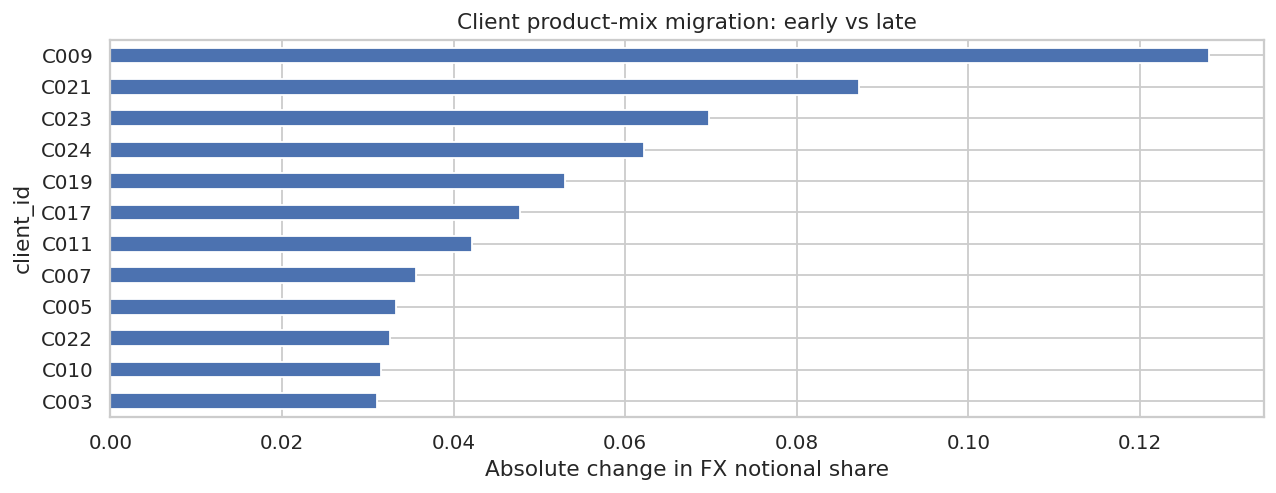

In [42]:
# Q22: early/late client product migration and sell-side share.
sol_migration=sol_enriched.copy()
mid_date=dates[len(dates)//2]
sol_migration['period']=np.where(sol_migration.trade_date<mid_date,'Early','Late')
sol_migration['fx_notional']=np.where(sol_migration.asset_class=='FX',sol_migration.notional_usd,0.)
sol_migration['is_sell']=sol_migration.side.eq(-1)
sol_period=(sol_migration.groupby(['client_id','period']).agg(
  notional=('notional_usd','sum'),fx_notional=('fx_notional','sum'),
  sell_share=('is_sell','mean'),fills=('fill_id','count')).reset_index())
sol_period['fx_share']=sol_period.fx_notional/sol_period.notional
sol_wide=sol_period.pivot(index='client_id',columns='period',values=['fx_share','sell_share','fills'])
sol_client_migration=pd.DataFrame({
  'fx_share_early':sol_wide['fx_share']['Early'],
  'fx_share_late':sol_wide['fx_share']['Late'],
  'sell_share_change':sol_wide['sell_share']['Late']-sol_wide['sell_share']['Early']})
sol_client_migration['abs_fx_change']=(sol_client_migration.fx_share_late-
                                       sol_client_migration.fx_share_early).abs()
display(sol_client_migration.sort_values('abs_fx_change',ascending=False).head(8))
fig,ax=plt.subplots(figsize=(10,4))
sol_client_migration.abs_fx_change.sort_values().tail(12).plot(kind='barh',ax=ax)
ax.set(xlabel='Absolute change in FX notional share',title='Client product-mix migration: early vs late');plt.tight_layout();plt.show()

## Solutions 23–28 — Performance, algorithms and production pipelines

In [43]:
# Q23: identical work, different implementations.
subset=sol_matched[['side','execution_price','mid']].copy()
t0=perf_counter()
for _ in range(25):
    a=np.array([r.side*(r.execution_price-r.mid)/r.mid*10000
                for r in subset.itertuples(index=False)])
loop_secs=perf_counter()-t0
t0=perf_counter()
for _ in range(25):
    b=(subset.side*(subset.execution_price-subset.mid)/subset.mid*10000).to_numpy()
vector_secs=perf_counter()-t0
assert np.allclose(a,b)
print(f'Loop: {loop_secs:.3f}s | vectorised: {vector_secs:.3f}s | '
      f'speed-up: {loop_secs/max(vector_secs,1e-12):.1f}× (environment dependent)')

# Q24: minimum table contracts and reconciliation.
assert fills.fill_id.is_unique and (fills.notional_usd>0).all()
assert fills.side.isin([-1,1]).all() and (fills.slippage_bps>=0).all()
assert len(sol_enriched)==len(fills)==len(sol_matched)
assert (sol_matched.quote_ts<=sol_matched.trade_ts).all()
assert np.isclose(fills.notional_usd.sum(),fills.groupby('trade_date').notional_usd.sum().sum())
print('Minimum table and temporal quality checks passed')

# Q25: pure Python accumulator and pandas equivalence
from collections import defaultdict
def accumulate(pairs:list[tuple[str,float]])->dict[str,float]:
    result=defaultdict(float)
    for cid,amount in pairs: result[cid]+=float(amount)
    return dict(result)

pairs=[('A',10),('B',5),('A',8),('B',3)]
assert accumulate(pairs)=={'A':18.0,'B':8.0}
assert pd.DataFrame(pairs,columns=['client','value']).groupby('client').value.sum().to_dict()==accumulate(pairs)

Loop: 0.166s | vectorised: 0.007s | speed-up: 22.1× (environment dependent)
Minimum table and temporal quality checks passed


In [44]:
# Q26: O(n) running window sum matches pandas 5-day rolling.
def max_window_sum(values,k:int)->tuple[int,float]:
    vals=np.asarray(values,dtype=float)
    if k<=0 or k>len(vals): raise ValueError('invalid window')
    running=float(vals[:k].sum())
    best=running;best_end=k-1
    for i in range(k,len(vals)):
        running+=float(vals[i]-vals[i-k])
        if running>best:best=running;best_end=i
    return best_end,best

best_day,best_amount=max_window_sum(sol_daily.notional_usd.to_numpy(),5)
pd_best=float(sol_daily.notional_usd.rolling(5).sum().max())
assert np.isclose(best_amount,pd_best)
print('Best 5-day C001 turnover ends on:',sol_daily.index[best_day].date(),
      '| USD:',f'{best_amount:,.0f}')

# Q27: keys must be instrument, assignment must be .loc, features must be backward-looking.
sol_fixed=fills.merge(products[['instrument','asset_class']],on='instrument',validate='many_to_one')
sol_fixed['new']=np.nan
sol_fixed.loc[sol_fixed.side==1,'new']=2*sol_fixed.loc[sol_fixed.side==1,'notional_usd']
sol_past_mid=quotes.sort_values('quote_ts').groupby('instrument').mid.shift(1)
assert len(sol_fixed)==len(fills) and sol_fixed.loc[sol_fixed.side==-1,'new'].isna().all()

Best 5-day C001 turnover ends on: 2025-03-12 | USD: 136,761,880


In [45]:
# Q28: small idempotent ETL with quarantined invalid current versions.
def clean_trade_events(raw:pd.DataFrame)->tuple[pd.DataFrame,pd.DataFrame]:
    required={'fill_id','version','notional_usd','side'}
    missing=required-set(raw.columns)
    if missing:raise KeyError(f'Missing required fields: {sorted(missing)}')
    latest=(raw.copy().sort_values(['fill_id','version'])
            .drop_duplicates('fill_id',keep='last'))
    bad=(latest.notional_usd<=0)|(~latest.side.isin([-1,1]))|latest.notional_usd.isna()
    rejected=latest.loc[bad].copy()
    rejected['reject_reason']=np.where(rejected.notional_usd<=0,'NONPOSITIVE_NOTIONAL',
                               np.where(rejected.notional_usd.isna(),'MISSING_NOTIONAL','BAD_SIDE'))
    accepted=latest.loc[~bad].copy()
    return (accepted.sort_values('fill_id').reset_index(drop=True),
            rejected.sort_values('fill_id').reset_index(drop=True))

sol_clean,sol_reject=clean_trade_events(fills_raw)
sol_clean_again,sol_reject_again=clean_trade_events(sol_clean)
pd.testing.assert_frame_equal(sol_clean,sol_clean_again)
assert sol_reject_again.empty and sol_clean.fill_id.is_unique
print('Accepted',len(sol_clean),'| rejected',len(sol_reject),'| idempotent yes')

Accepted 7996 | rejected 4 | idempotent yes


## Worked mock interview A — reference solution

This intentionally treats `execution_price − dealer mid` as a *stylised execution-cost proxy*. In production confirm benchmark suitability, transaction currencies, product multipliers, settlement conventions and risk controls before comparing dollars.

Client execution report:
Unmatched/stale quote rows: 0


,client_id,fills,notional_usd,cost_usd,weighted_cost_bp
21,C022,90,"701,602,007.495","458,127.279",6.530
17,C018,82,"684,617,075.599","442,213.972",6.459
0,C001,80,"723,525,456.080","466,928.843",6.454
8,C009,74,"649,312,096.175","418,668.107",6.448
14,C015,79,"637,623,583.530","407,637.790",6.393
12,C013,69,"666,087,927.203","424,815.620",6.378
11,C012,74,"652,013,168.759","415,102.550",6.366
13,C014,78,"651,536,581.621","409,166.447",6.280


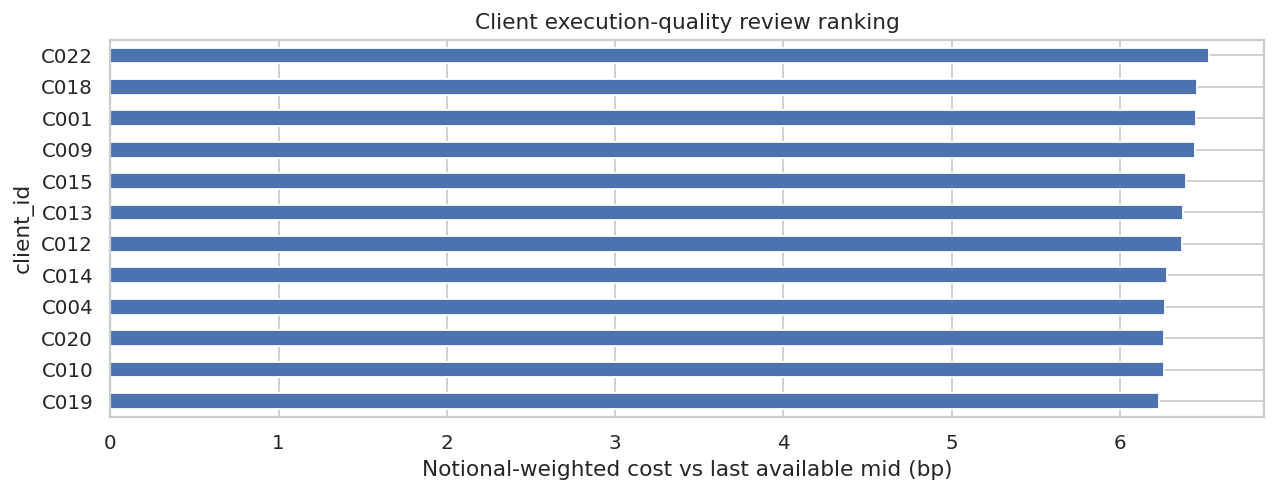

In [46]:
def client_execution_report(fills_df:pd.DataFrame,quotes_df:pd.DataFrame,
                            asof:pd.Timestamp,min_turnover:float=100e6)->tuple[pd.DataFrame,pd.DataFrame]:
    cutoff_date=pd.bdate_range(end=asof.normalize(),periods=60)[0]
    recent=fills_df.loc[(fills_df.trade_ts<=asof)&(fills_df.trade_date>=cutoff_date)].copy()
    available_quotes=quotes_df.loc[quotes_df.quote_ts<=asof].copy()
    joined=pd.merge_asof(recent.sort_values('trade_ts'),available_quotes.sort_values('quote_ts'),
       left_on='trade_ts',right_on='quote_ts',by='instrument',direction='backward',
       tolerance=pd.Timedelta('8h'))
    joined['stale_or_missing_quote']=joined.mid.isna()
    valid=joined.loc[~joined.stale_or_missing_quote].copy()
    valid['edge_cost_bp']=valid.side*(valid.execution_price-valid.mid)/valid.mid*10000
    valid['cost_usd']=valid.edge_cost_bp*valid.notional_usd/10000
    summary=(valid.groupby('client_id').agg(fills=('fill_id','count'),
             notional_usd=('notional_usd','sum'),cost_usd=('cost_usd','sum')).reset_index())
    summary['weighted_cost_bp']=summary.cost_usd/summary.notional_usd*10000
    summary=summary.loc[summary.notional_usd>=min_turnover].sort_values('weighted_cost_bp',ascending=False)
    assert len(joined)==len(recent) and (valid.quote_ts<=valid.trade_ts).all()
    return summary,joined

sol_exec_summary,sol_all_matches=client_execution_report(
    fills,quotes,asof=dates[-1]+pd.Timedelta(hours=16))
print('Client execution report:');display(sol_exec_summary.head(8))
print('Unmatched/stale quote rows:',int(sol_all_matches.stale_or_missing_quote.sum()))
fig,ax=plt.subplots(figsize=(10,4))
sol_exec_summary.head(12).sort_values('weighted_cost_bp').set_index('client_id').weighted_cost_bp.plot(kind='barh',ax=ax)
ax.set(xlabel='Notional-weighted cost vs last available mid (bp)',title='Client execution-quality review ranking')
plt.tight_layout();plt.show()

## Worked mock interview B — reference solution

40-business-day windows use `date → day index → window ID`; the feature table remains one row per client/window. Zero-trade client-windows should be represented explicitly in a production feature store rather than omitted.

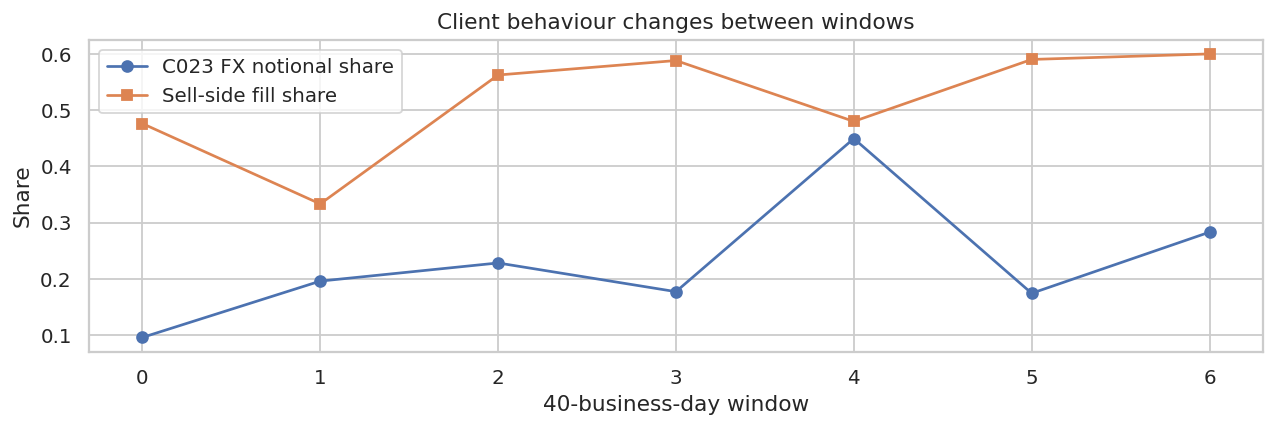

In [47]:
sol_windowed=sol_enriched.merge(market[['date','day_idx']],left_on='trade_date',right_on='date',validate='many_to_one')
sol_windowed['window_id']=sol_windowed.day_idx//40
sol_windowed['fx_notional_usd']=np.where(sol_windowed.asset_class=='FX',sol_windowed.notional_usd,0)
sol_windowed['sell_flag']=sol_windowed.side.eq(-1)
sol_win=(sol_windowed.groupby(['client_id','window_id']).agg(
     n_fills=('fill_id','count'),total_usd=('notional_usd','sum'),
     fx_usd=('fx_notional_usd','sum'),sell_share=('sell_flag','mean')).reset_index())
sol_win['fx_share']=sol_win.fx_usd/sol_win.total_usd
sol_win=sol_win.sort_values(['client_id','window_id'])
sol_win['delta_fx_share']=sol_win.groupby('client_id').fx_share.diff()
sol_win['peer_median_delta']=(sol_win.groupby('window_id').delta_fx_share.transform('median'))
sol_win['idiosyncratic_delta']=sol_win.delta_fx_share-sol_win.peer_median_delta
assert sol_win[['client_id','window_id']].duplicated().sum()==0
assert sol_win.fx_share.between(0,1).all()
assert sol_win.groupby('client_id').delta_fx_share.apply(lambda x:pd.isna(x.iloc[0])).all()
worst_shift=sol_win.dropna(subset=['idiosyncratic_delta']).assign(
    shift_magnitude=lambda d:d.idiosyncratic_delta.abs()).nlargest(1,'shift_magnitude').iloc[0]
sol_focus=sol_win.loc[sol_win.client_id==worst_shift.client_id]
fig,ax=plt.subplots(figsize=(10,3.5))
ax.plot(sol_focus.window_id,sol_focus.fx_share,'o-',label=f'{worst_shift.client_id} FX notional share')
ax.plot(sol_focus.window_id,sol_focus.sell_share,'s-',label='Sell-side fill share')
ax.set(xlabel='40-business-day window',ylabel='Share',title='Client behaviour changes between windows')
ax.legend();plt.tight_layout();plt.show()

# Quick oral interview flashcards

Use these as **30-second answers** before a coding session.

| Question | Interview-ready answer |
|---|---|
| `loc` vs `iloc`? | Labels vs integer positions; different slicing endpoint rules. |
| `merge` vs `concat`? | Relational join by keys vs append/align objects along an axis. |
| `agg` vs `transform`? | One record per group vs one value per original row. |
| `apply` vs vectorise? | `apply` is flexible but often runs Python work per row; prefer column operations where possible. |
| Why `validate='many_to_one'`? | It detects duplicate reference keys that could multiply financial totals. |
| Why `merge_asof(..., backward)`? | Prevents matching a trade with a quote known only in the future. |
| What does `.shift(1)` mean? | Access the previous observation (within correct ordered groups); frequently required to avoid leakage. |
| `pivot` vs `pivot_table`? | `pivot` needs unique keys; `pivot_table` supports aggregation over duplicate combinations. |
| Why use weighted execution costs? | Large tickets should contribute proportionally to the metric. |
| `.resample` vs `.rolling`? | Rebucket timestamps into a new frequency vs compute a moving window on a series. |
| When is missing-data imputation unsafe? | When missing means business exception, or when imputation learns from future/test observations. |
| Why check join cardinality? | An unintended many-to-many merge silently exaggerates position, turnover or P&L. |
| What is group leakage? | Same client/instrument/time event appears across train/test so generalisation seems better than it is. |
| Performance basics? | Columnar operations, appropriate dtypes, selective columns, avoid per-row `apply` and unnecessary copies; profile first. |
| What is a robust pipeline? | Typed contracts, idempotent corrections, timestamp lineage, error quarantine, reconciliation, tests and monitoring. |

## Suggested 3-day practice plan

- **Day 1:** Q01–Q10. Focus on speed and correctness; answer every “why” question aloud.
- **Day 2:** Q11–Q22. Rebuild transformations without hints and test joins/time alignment.
- **Day 3:** Q23–Q28, Mock A and Mock B under a timer. After each task, add one edge-case unit test.

**Final advice:** In a senior interview, the fastest answer isn't necessarily best. Explain financial units, data grain, point-in-time validity, source reliability and a testable baseline while coding.